# Autoregressive forecasting with transformer oil temperature

<a target="_blank" href="https://colab.research.google.com/github/changyaochen/MECE4520/blob/master/site/sequential-models/01-autoregressive-models.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

An **autoregressive (AR)** model predicts the next value of a time series from a fixed number of its own earlier values. In this notebook, we use hourly transformer oil-temperature measurements from the [ETT-small dataset](https://github.com/zhouhaoyi/ETDataset/tree/main/ETT-small) to build and test AR($p$) models.

The central question is: **how much recent history should the model use?**

## What you will do

1. Load one real hourly transformer oil-temperature series.
2. Create a chronological training/test split.
3. Express an AR($p$) model as ordinary linear regression on lagged values.
4. Compare one-step-ahead and recursive multi-step forecasts.
5. Compare AR(1), AR(6), AR(24), and AR(168) on the same held-out hours.

## 1. Define the forecasting task

Let $X_t$ be oil temperature at hour $t$. An autoregressive model of order $p$ uses the preceding $p$ measurements:

$$
\widehat{X}_t = \beta_0 + \beta_1 X_{t-1} + \cdots + \beta_p X_{t-p}.
$$

This is a linear-regression model. Its features are simply the past values $X_{t-1}, X_{t-2}, \ldots, X_{t-p}$, arranged in a time-respecting order.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
palette = sns.color_palette("deep")
observed_color = palette[0]
forecast_color = palette[1]
train_color = palette[2]
test_color = palette[3]


In [2]:
DATA_URL = (
    "https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/"
    "ETT-small/ETTh1.csv"
)
data_path = Path("ETTh1.csv")

# Google Colab has a temporary local file system. Download the public data
# only if it is not already available there.
if not data_path.exists():
    urlretrieve(url=DATA_URL, filename=data_path)

raw_data = pd.read_csv(filepath_or_buffer=data_path)
raw_data.head()


,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
0,2016-07-01 00:00:00,5.827,2.009,1.599,0.462,4.203,1.340,30.531000
1,2016-07-01 01:00:00,5.693,2.076,1.492,0.426,4.142,1.371,27.787001
2,2016-07-01 02:00:00,5.157,1.741,1.279,0.355,3.777,1.218,27.787001
3,2016-07-01 03:00:00,5.090,1.942,1.279,0.391,3.807,1.279,25.044001
4,2016-07-01 04:00:00,5.358,1.942,1.492,0.462,3.868,1.279,21.948000


The ETT-small file contains the timestamp, oil temperature (`OT`), and several load-related measurements. For this first notebook, we deliberately use only `OT`.

A short part of the early `OT` record repeats exactly for 24 consecutive hours. We treat that as a data artifact. To preserve an evenly sampled, contiguous series, we retain only the observations before that artifact when making the chronological split.

In [3]:
def truncate_before_repeated_value_artifact(frame: pd.DataFrame) -> pd.DataFrame:
    """Keep the contiguous observations before the repeated `OT` run.

    Args:
        frame: ETT-small observations with an `OT` column.

    Returns:
        A copy ending immediately before the repeated run.
    """
    run_id = frame["OT"].ne(frame["OT"].shift()).cumsum()
    run_length = frame.groupby(run_id)["OT"].transform("size")
    artifact_start = run_length.ge(24).idxmax()
    return frame.iloc[:artifact_start].copy()

data = raw_data.dropna(subset=["OT"]).iloc[:1000].copy()
data = truncate_before_repeated_value_artifact(frame=data)
data["date"] = pd.to_datetime(data["date"])
data = data.reset_index(drop=True)

values = data["OT"].to_numpy(dtype=float)
dates = data["date"]
TRAIN_END = 500

print(f"Contiguous observations retained: {len(data):,}")
print(f"Training observations: {TRAIN_END:,}")
print(f"Held-out observations: {len(data) - TRAIN_END:,}")
data[["date", "OT"]].head()


Contiguous observations retained: 720
Training observations: 500
Held-out observations: 220


,date,OT
0,2016-07-01 00:00:00,30.531000
1,2016-07-01 01:00:00,27.787001
2,2016-07-01 02:00:00,27.787001
3,2016-07-01 03:00:00,25.044001
4,2016-07-01 04:00:00,21.948000


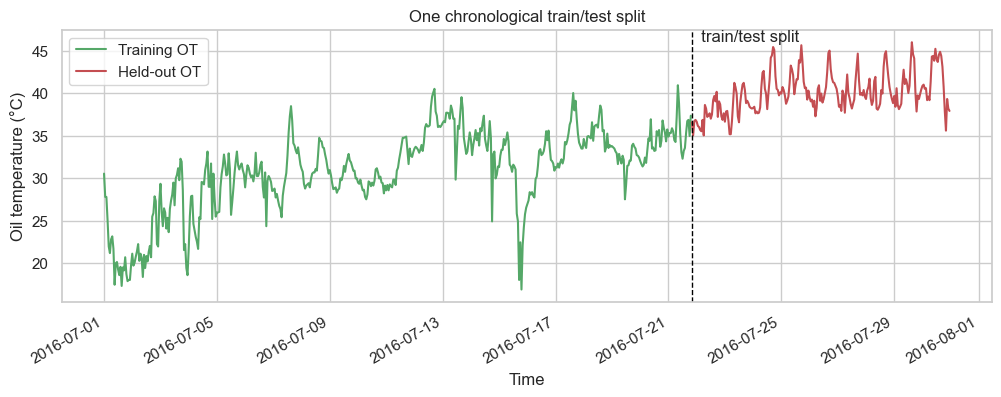

In [4]:
figure, axis = plt.subplots(figsize=(12, 4))
axis.plot(dates.iloc[:TRAIN_END], values[:TRAIN_END], color=train_color, label="Training OT")
axis.plot(dates.iloc[TRAIN_END:], values[TRAIN_END:], color=test_color, label="Held-out OT")
axis.axvline(dates.iloc[TRAIN_END], color="black", linestyle="--", linewidth=1)
axis.text(dates.iloc[TRAIN_END], axis.get_ylim()[1], "  train/test split", va="top")
axis.set(title="One chronological train/test split", xlabel="Time", ylabel="Oil temperature (°C)")
axis.legend(frameon=True)
figure.autofmt_xdate()
plt.show()


## 2. Turn a time series into a regression dataset

For AR(3), the row used to predict $X_t$ is

$$
[X_{t-1}, X_{t-2}, X_{t-3}] \quad \longrightarrow \quad X_t.
$$

The newest lag is kept first. The next function builds those rows without shuffling time.

In [5]:
def make_lagged_regression_data(
    values: np.ndarray,
    order: int,
) -> tuple[np.ndarray, np.ndarray]:
    """Create AR features and targets from one ordered series.

    Args:
        values: Ordered observations of one time series.
        order: Number of earlier observations used by the AR model.

    Returns:
        A tuple containing a feature matrix with columns ordered from
        newest lag to oldest lag, and the matching next-value targets.
    """
    features = np.array(
        [values[index - order : index][::-1] for index in range(order, len(values))]
    )
    targets = values[order:]
    return features, targets

example_features, example_targets = make_lagged_regression_data(
    values=values[:8],
    order=3,
)
pd.DataFrame(
    example_features,
    columns=["OT at t-1", "OT at t-2", "OT at t-3"],
).assign(**{"OT at t": example_targets})


,OT at t-1,OT at t-2,OT at t-3,OT at t
0,27.787001,27.787001,30.531000,25.044001
1,25.044001,27.787001,27.787001,21.948000
2,21.948000,25.044001,27.787001,21.174000
3,21.174000,21.948000,25.044001,22.792000
4,22.792000,21.174000,21.948000,23.143999


## 3. Fit one AR model on the training period

We estimate the intercept and the $p$ coefficients by ordinary least squares. Only the earlier training observations are used to estimate them.

In [6]:
def fit_ar_model(values: np.ndarray, order: int) -> tuple[float, np.ndarray]:
    """Fit an ordinary least-squares AR model.

    Args:
        values: Training observations in chronological order.
        order: Number of lagged observations used as features.

    Returns:
        The fitted intercept and coefficient vector, ordered from the
        newest lag to the oldest lag.
    """
    features, targets = make_lagged_regression_data(values=values, order=order)
    model = LinearRegression()
    model.fit(features, targets)
    return float(model.intercept_), model.coef_

ORDER = 24
intercept, coefficients = fit_ar_model(values=values[:TRAIN_END], order=ORDER)

coefficient_table = pd.DataFrame(
    {"coefficient": coefficients},
    index=[f"OT at t-{lag}" for lag in range(1, ORDER + 1)],
)
print(f"AR({ORDER}) intercept: {intercept:.3f}")
coefficient_table.head(8)


AR(24) intercept: 1.726


,coefficient
OT at t-1,0.791183
OT at t-2,0.088113
OT at t-3,0.009705
OT at t-4,-0.048881
OT at t-5,-0.002692
OT at t-6,0.016473
OT at t-7,0.000783
OT at t-8,0.035783


## 4. One-step-ahead versus recursive multi-step forecasting

There are two useful forecasting modes.

- **One-step-ahead forecasting (observed lags):** every prediction uses the actual preceding temperature measurements. This applies when the newest measurement is available before predicting the next hour.
- **Recursive multi-step forecasting (predicted lags):** after the split, each prediction is fed back as an input to the next prediction. This applies when we need a complete future trajectory before the future temperatures have been observed.

The explorer uses these same two forecasting-mode labels.

In [7]:
def one_step_forecast(
    values: np.ndarray,
    order: int,
    intercept: float,
    coefficients: np.ndarray,
    start_index: int,
) -> np.ndarray:
    """Make one-step-ahead forecasts using the actual preceding observations.

    Args:
        values: Full observed series, including the held-out period.
        order: Number of autoregressive lags.
        intercept: Fitted AR intercept.
        coefficients: Fitted AR coefficients.
        start_index: First held-out time index to predict.

    Returns:
        A vector with missing values before `start_index` and one-step
        one-step-ahead predictions from that index onward.
    """
    predictions = np.full(len(values), np.nan)
    for index in range(start_index, len(values)):
        actual_lags = values[index - order : index][::-1]
        predictions[index] = intercept + np.dot(coefficients, actual_lags)
    return predictions


def recursive_forecast(
    order: int,
    intercept: float,
    coefficients: np.ndarray,
    initial_history: np.ndarray,
    forecast_steps: int,
) -> np.ndarray:
    """Make a recursive multi-step forecast by feeding predictions into later lags.

    Args:
        order: Number of autoregressive lags.
        intercept: Fitted AR intercept.
        coefficients: Fitted AR coefficients.
        initial_history: Observations available at the train/test boundary.
        forecast_steps: Number of future values to generate.

    Returns:
        Recursive multi-step forecasts in chronological order.
    """
    history = list(initial_history)
    predictions: list[float] = []
    for _ in range(forecast_steps):
        lag_values = np.asarray(history[-order:][::-1])
        prediction = float(intercept + np.dot(coefficients, lag_values))
        predictions.append(prediction)
        history.append(prediction)
    return np.asarray(predictions)


def root_mean_squared_error(observed: np.ndarray, predicted: np.ndarray) -> float:
    """Compute root mean squared error in oil-temperature units.

    Args:
        observed: Measured values.
        predicted: Corresponding model predictions.

    Returns:
        Root mean squared error.
    """
    return float(np.sqrt(np.mean((observed - predicted) ** 2)))


In [8]:
one_step_predictions = one_step_forecast(
    values=values,
    order=ORDER,
    intercept=intercept,
    coefficients=coefficients,
    start_index=TRAIN_END,
)
recursive_predictions = recursive_forecast(
    order=ORDER,
    intercept=intercept,
    coefficients=coefficients,
    initial_history=values[:TRAIN_END],
    forecast_steps=len(values) - TRAIN_END,
)

test_values = values[TRAIN_END:]
one_step_rmse = root_mean_squared_error(
    observed=test_values,
    predicted=one_step_predictions[TRAIN_END:],
)
recursive_rmse = root_mean_squared_error(
    observed=test_values,
    predicted=recursive_predictions,
)

forecast_summary = pd.DataFrame(
    {"test RMSE (°C)": [one_step_rmse, recursive_rmse]},
    index=["One-step-ahead", "Recursive multi-step"],
)
forecast_summary


,test RMSE (°C)
One-step-ahead,1.362854
Recursive multi-step,6.957761


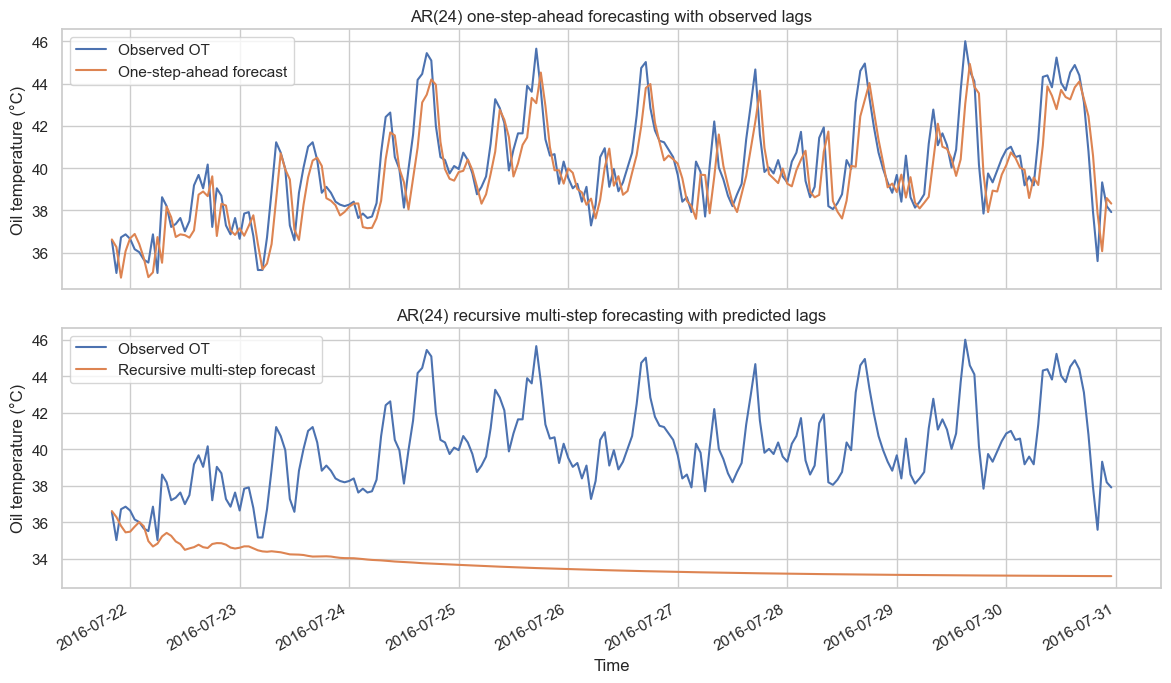

In [9]:
test_dates = dates.iloc[TRAIN_END:]
figure, axes = plt.subplots(nrows=2, figsize=(12, 7), sharex=True)

axes[0].plot(test_dates, test_values, color=observed_color, label="Observed OT")
axes[0].plot(test_dates, one_step_predictions[TRAIN_END:], color=forecast_color, label="One-step-ahead forecast")
axes[0].set(title=f"AR({ORDER}) one-step-ahead forecasting with observed lags", ylabel="Oil temperature (°C)")
axes[0].legend(frameon=True)

axes[1].plot(test_dates, test_values, color=observed_color, label="Observed OT")
axes[1].plot(test_dates, recursive_predictions, color=forecast_color, label="Recursive multi-step forecast")
axes[1].set(title=f"AR({ORDER}) recursive multi-step forecasting with predicted lags", xlabel="Time", ylabel="Oil temperature (°C)")
axes[1].legend(frameon=True)
figure.autofmt_xdate()
figure.tight_layout()
plt.show()


## 5. Compare different history lengths

A higher order gives the model a longer fixed history window and more coefficients to estimate. It does **not** guarantee lower held-out error: the extra lags may add redundant information or may make the fitted coefficients less stable.

We fit every candidate on exactly the same earlier data and compare both forecasting modes on exactly the same later observations.

In [10]:
ORDERS = (1, 6, 24, 168)
comparison_rows: list[dict[str, float | int]] = []

for order in ORDERS:
    candidate_intercept, candidate_coefficients = fit_ar_model(
        values=values[:TRAIN_END],
        order=order,
    )
    candidate_one_step = one_step_forecast(
        values=values,
        order=order,
        intercept=candidate_intercept,
        coefficients=candidate_coefficients,
        start_index=TRAIN_END,
    )
    candidate_recursive = recursive_forecast(
        order=order,
        intercept=candidate_intercept,
        coefficients=candidate_coefficients,
        initial_history=values[:TRAIN_END],
        forecast_steps=len(values) - TRAIN_END,
    )
    comparison_rows.append(
        {
            "order p": order,
            "one-step-ahead test RMSE (°C)": root_mean_squared_error(
                observed=test_values,
                predicted=candidate_one_step[TRAIN_END:],
            ),
            "recursive multi-step test RMSE (°C)": root_mean_squared_error(
                observed=test_values,
                predicted=candidate_recursive,
            ),
        }
    )

comparison = pd.DataFrame(comparison_rows).set_index("order p")
comparison.style.format("{:.3f}")


,one-step-ahead test RMSE (°C),recursive multi-step test RMSE (°C)
order p,,
1,1.479,9.099
6,1.437,8.462
24,1.363,6.958
168,2.016,7.659


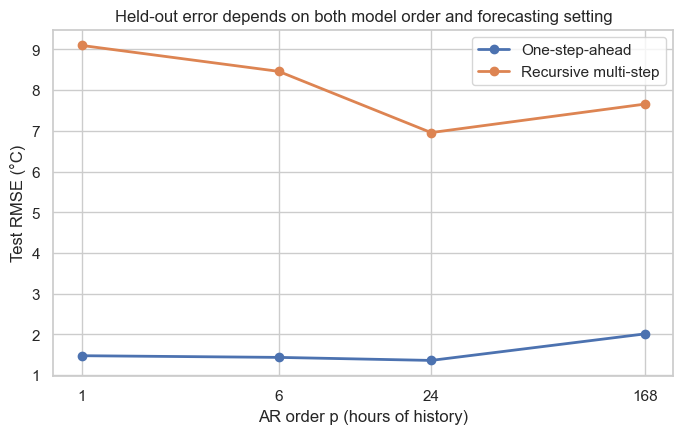

In [11]:
figure, axis = plt.subplots(figsize=(8, 4.5))
axis.plot(
    comparison.index,
    comparison["one-step-ahead test RMSE (°C)"],
    marker="o",
    linewidth=2,
    label="One-step-ahead",
)
axis.plot(
    comparison.index,
    comparison["recursive multi-step test RMSE (°C)"],
    marker="o",
    linewidth=2,
    label="Recursive multi-step",
)
axis.set_xscale("log", base=2)
axis.set_xticks(ORDERS, labels=[str(order) for order in ORDERS])
axis.set(
    title="Held-out error depends on both model order and forecasting setting",
    xlabel="AR order p (hours of history)",
    ylabel="Test RMSE (°C)",
)
axis.legend(frameon=True)
plt.show()


## Takeaways

- AR($p$) is ordinary linear regression whose features are $p$ ordered lags of the same series.
- A chronological split matters: future hours cannot be used to fit a model for earlier hours.
- One-step-ahead forecasting uses observed lags; recursive multi-step forecasting instead feeds its own predictions forward as lags.
- More lags do not automatically produce a better held-out forecast.

[Open the autoregressive explorer](01-autoregressive-models-explorer.qmd)  
[← Return to Sequential models](index.qmd)